# 02 · Preparación: exclusiones, embeddings, grupos y partición 60/10/30

**Fase CRISP-DM:** 3. Preparación de los datos.
**Entrada:** `manifest/manifest_v0.csv` y el zip de `raw/` (notebook 01).

**Qué hace**
1. Excluye duplicados exactos (md5) conservando 1 imagen por grupo, sin borrar archivos.
2. Calcula embeddings **DINOv2-ViT-L/14** (encoder recomendado por Stein et al., 2023) para todas las imágenes.
3. Analiza casi duplicados: **tú fijas el umbral** mirando pares de ejemplo.
4. Agrupa casi duplicados en `group_id` y hace la partición **60/10/30 estratificada por clase y por grupos**.
5. Verifica que no haya fuga entre particiones y genera un zip con carpetas `train/val/test/<clase>/`.
6. Guarda la **línea base de distancias al vecino más cercano** (real→entrenamiento) para calibrar memorización.

**Cómo ejecutarlo:** *Parte A* (pasos 1–7) de corrido → revisas los pares → fijas `UMBRAL_SIM` en el paso 8 → *Parte B* (pasos 8–15).

**Entorno:** *Entorno de ejecución → Cambiar tipo* → **GPU T4** (suficiente).

# Parte A
## Paso 1 · Entorno

In [1]:
import sys, platform, os, subprocess
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
gpu = subprocess.run("nvidia-smi --query-gpu=name,memory.total --format=csv,noheader", shell=True,
                     capture_output=True, text=True).stdout.strip()
print("Python:", sys.version.split()[0], "| ¿Colab?:", IN_COLAB)
print("GPU:", gpu if gpu else "⚠️ NINGUNA: cambia el entorno a GPU antes del Paso 5")

Python: 3.13.16 | ¿Colab?: True
GPU: ⚠️ NINGUNA: cambia el entorno a GPU antes del Paso 5


## Paso 2 · Importaciones, semilla y rutas

In [2]:
import json, shutil, hashlib, random, zipfile, time
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import sklearn
from sklearn.manifold import TSNE
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED); np.random.seed(SEED)
PROPORCIONES = {"train": 0.60, "val": 0.10, "test": 0.30}

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = Path("/content/drive/MyDrive/tesis_retail")
    LOCAL_DIR = Path("/content/data")
else:
    PROJECT_DIR = Path(os.environ.get("PROJECT_DIR", "./tesis_retail")).resolve()
    LOCAL_DIR = Path(os.environ.get("LOCAL_DIR", "./data_local")).resolve()

DIRS = {k: PROJECT_DIR / k for k in ["raw", "manifest", "embeddings", "eda", "eda/pares", "logs", "splits"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
LOCAL_DIR.mkdir(parents=True, exist_ok=True)

LOG01 = json.loads((DIRS["logs"] / "01_inventario.json").read_text())
ZIP_NAME = LOG01["zip"]["nombre"]
print("Proyecto:", PROJECT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Proyecto: /content/drive/MyDrive/tesis_retail


## Paso 3 · Recuperar las imágenes en el disco local (y verificar que el zip es el mismo del notebook 01)

In [3]:
def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

ZIP_LOCAL = LOCAL_DIR / ZIP_NAME
EXTRACT_DIR = LOCAL_DIR / "grocpos_v4"
if not ZIP_LOCAL.exists():
    shutil.copy2(DIRS["raw"] / ZIP_NAME, ZIP_LOCAL)
sha = sha256_file(ZIP_LOCAL)
assert sha == LOG01["zip"]["sha256"], "⚠️ El zip NO coincide con el del notebook 01. Detente y revisa."
print("SHA-256 coincide con el notebook 01 ✔")
if not EXTRACT_DIR.exists():
    with zipfile.ZipFile(ZIP_LOCAL) as zf:
        zf.extractall(EXTRACT_DIR)

m = pd.read_csv(DIRS["manifest"] / "manifest_v0.csv")
faltan = [r for r in m["ruta_rel"] if not (EXTRACT_DIR / r).exists()]
assert not faltan, f"Faltan {len(faltan)} archivos en disco"
print("Manifiesto v0:", m.shape, "| todas las imágenes encontradas ✔")

SHA-256 coincide con el notebook 01 ✔
Manifiesto v0: (5203, 31) | todas las imágenes encontradas ✔


## Paso 4 · Exclusiones (sin borrar archivos)
Se conserva **una** imagen por grupo md5 (la primera en orden alfabético de ruta, para que sea reproducible) y se marcan las demás con `excluir=True`.

In [4]:
m["excluir"] = False
m["motivo_exclusion"] = ""
m.loc[~m["abre_ok"].astype(bool), ["excluir", "motivo_exclusion"]] = [True, "corrupta"]

orden = m.sort_values("ruta_rel").index
dup = m.loc[orden, "md5"].duplicated(keep="first")
idx_dup = dup[dup].index
m.loc[idx_dup, ["excluir", "motivo_exclusion"]] = [True, "duplicado_md5"]

print(m["motivo_exclusion"].replace("", "conservada").value_counts().to_string())
kept_por_clase = m[~m["excluir"]]["clase"].value_counts().sort_index()
print("\nImágenes conservadas:", int((~m["excluir"]).sum()))
print("Por clase: min", kept_por_clase.min(), "| max", kept_por_clase.max())
if kept_por_clase.nunique() > 1:
    print("⚠️ Las clases no quedaron con el mismo número de imágenes:\n", kept_por_clase.to_string())

motivo_exclusion
conservada       5100
duplicado_md5     103

Imágenes conservadas: 5100
Por clase: min 300 | max 300


## Paso 5 · Embeddings DINOv2-ViT-L/14 (GPU)

- Modelo cargado desde el repositorio oficial con `torch.hub` (`facebookresearch/dinov2`, `dinov2_vitl14`). Devuelve un vector de 1024 dimensiones por imagen (token CLS).
- Preprocesamiento: redimensionar a 224×224 (bicúbico) y normalizar con media/desviación de ImageNet. **Este mismo preprocesamiento se usará al evaluar las imágenes sintéticas**, para que el espacio sea idéntico.
- Se calculan para las 5203 imágenes (también las excluidas) y se guardan en Drive. Si ya existen, se cargan y no se recalculan.
- Avisos sobre `xFormers` al cargar el modelo son normales y no afectan.

In [5]:
import torch
import torchvision
import torchvision.transforms as T

EMB_PATH = DIRS["embeddings"] / "dinov2_vitl14_v0.npy"
EMB_IDS = DIRS["embeddings"] / "dinov2_vitl14_v0_ids.csv"
EMB_CFG = {"repo": "facebookresearch/dinov2", "modelo": "dinov2_vitl14", "salida": "CLS (1024-d)",
           "resize": "224x224 bicubico", "normalizacion": "ImageNet mean/std",
           "torch": torch.__version__, "torchvision": torchvision.__version__}

if EMB_PATH.exists() and EMB_IDS.exists() and \
        pd.read_csv(EMB_IDS)["image_id"].tolist() == m["image_id"].tolist():
    EMB = np.load(EMB_PATH)
    print("Embeddings cargados desde Drive:", EMB.shape)
else:
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
    assert DEVICE == "cuda", "Activa la GPU (Paso 1)."
    torch.manual_seed(SEED)
    model = torch.hub.load("facebookresearch/dinov2", "dinov2_vitl14").eval().to(DEVICE)
    TF = T.Compose([
        T.Resize((224, 224), interpolation=T.InterpolationMode.BICUBIC),
        T.ToTensor(),
        T.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ])

    class DS(torch.utils.data.Dataset):
        def __init__(self, rutas): self.rutas = rutas
        def __len__(self): return len(self.rutas)
        def __getitem__(self, i):
            with Image.open(EXTRACT_DIR / self.rutas[i]) as im:
                return TF(im.convert("RGB"))

    loader = torch.utils.data.DataLoader(DS(m["ruta_rel"].tolist()), batch_size=64,
                                         shuffle=False, num_workers=2, pin_memory=True)
    feats = []
    with torch.inference_mode():
        for x in tqdm(loader, desc="DINOv2"):
            feats.append(model(x.to(DEVICE, non_blocking=True)).float().cpu().numpy())
    EMB = np.concatenate(feats).astype(np.float32)
    np.save(EMB_PATH, EMB)
    m[["image_id"]].to_csv(EMB_IDS, index=False)
    print("Embeddings calculados y guardados:", EMB.shape)

assert EMB.shape[0] == len(m)

Embeddings cargados desde Drive: (5203, 1024)


## Paso 6 · Similitud entre imágenes de la misma clase

Se usa **similitud coseno** (1 = idénticas en el espacio DINOv2). Para cada imagen conservada se busca su vecino más parecido dentro de su clase.
También se listan los pares más parecidos **entre clases distintas** (posibles errores de etiqueta o clases casi iguales).

In [6]:
keep = m[~m["excluir"]].copy()
idx_keep = keep.index.to_numpy()
E = EMB[idx_keep]
En = E / np.linalg.norm(E, axis=1, keepdims=True)
pos = {iid: k for k, iid in enumerate(keep["image_id"])}

SIM_MIN_PARES = 0.80        # solo se guardan pares por encima de esto (para no llenar memoria)
pares, nn_sim = [], np.zeros(len(keep))
for clase, sub in keep.groupby("clase"):
    ii = np.array([pos[i] for i in sub["image_id"]])
    S = En[ii] @ En[ii].T
    np.fill_diagonal(S, -1)
    nn_sim[ii] = S.max(1)
    a, b = np.where(np.triu(S, 1) >= SIM_MIN_PARES)
    for x, y in zip(a, b):
        pares.append((sub["image_id"].iloc[x], sub["image_id"].iloc[y], clase, float(S[x, y])))
pares = pd.DataFrame(pares, columns=["a", "b", "clase", "sim"]).sort_values("sim", ascending=False)
keep["nn_sim_intraclase"] = nn_sim
print(f"Pares intraclase con sim ≥ {SIM_MIN_PARES}: {len(pares)}")

# Pares pHash idénticos (referencia de 'casi duplicado seguro')
ph = keep[keep.duplicated("phash", keep=False)].groupby("phash")["image_id"].apply(list)
ref_phash = []
for ids in ph:
    for i in range(len(ids)):
        for j in range(i + 1, len(ids)):
            ref_phash.append(float(En[pos[ids[i]]] @ En[pos[ids[j]]]))
print("Similitud de los pares pHash idénticos (referencia):", np.round(sorted(ref_phash), 4))

# Pares entre clases distintas más parecidos
S_all = En @ En.T
mismo = keep["clase"].to_numpy()[:, None] == keep["clase"].to_numpy()[None, :]
S_all[mismo] = -1
a, b = np.unravel_index(np.argsort(S_all, axis=None)[::-1][:40:2], S_all.shape)
inter = pd.DataFrame({"a": keep["image_id"].to_numpy()[a], "clase_a": keep["clase"].to_numpy()[a],
                      "b": keep["image_id"].to_numpy()[b], "clase_b": keep["clase"].to_numpy()[b],
                      "sim": S_all[a, b]})
del S_all
inter.head(10)

Pares intraclase con sim ≥ 0.8: 388817
Similitud de los pares pHash idénticos (referencia): [0.9619 0.9873 0.9886 0.9903 0.9959 0.9971 0.9976]


,a,clase_a,b,clase_b,sim
0,img_01072,7622201673222-dairyMilk-65g,img_05107,8964002759095-rio-70g,0.880201
1,img_05182,8964002759095-rio-70g,img_00305,0870572007376-yums-10g,0.877892
2,img_05034,8964002759095-rio-70g,img_01156,7622201673222-dairyMilk-65g,0.875373
3,img_05071,8964002759095-rio-70g,img_00305,0870572007376-yums-10g,0.871239
4,img_05092,8964002759095-rio-70g,img_00305,0870572007376-yums-10g,0.870727
5,img_05108,8964002759095-rio-70g,img_00313,0870572007376-yums-10g,0.870003
6,img_05010,8964002759095-rio-70g,img_01156,7622201673222-dairyMilk-65g,0.869100
7,img_01175,7622201673222-dairyMilk-65g,img_00305,0870572007376-yums-10g,0.868125
8,img_05108,8964002759095-rio-70g,img_00305,0870572007376-yums-10g,0.867577
9,img_01175,7622201673222-dairyMilk-65g,img_05092,8964002759095-rio-70g,0.867485


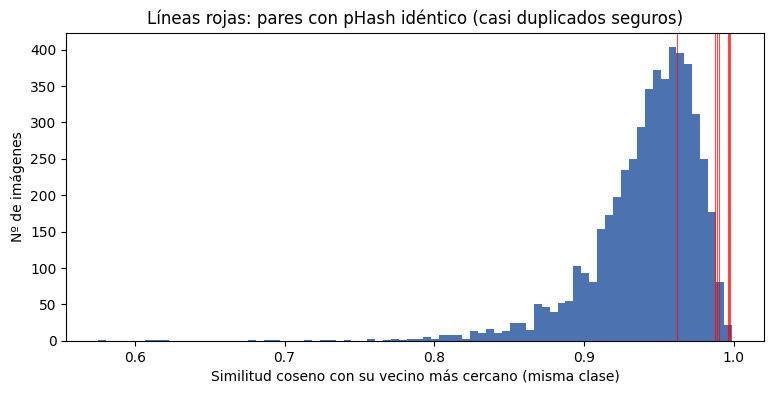

count    5100.0000
mean        0.9417
std         0.0363
min         0.5753
50%         0.9487
90%         0.9779
95%         0.9836
99%         0.9905
max         0.9988

Resumen por clase (mediana de similitud al vecino):
clase
01200080175-pepsi-500ml                0.9807
0870572007376-yums-10g                 0.9657
891008219561-milkPack-1lr              0.9651
8961014246834-lifebouyShampoo-175ml    0.9649
8964000090619-laysFrenchCheese-14g     0.9643
620514018256-nationalKetchup-50g       0.9567
8006540978313-areilSurf-40g            0.9555
8964000346334-olper-1.5ltr             0.9518
7622201718664-tang-25g                 0.9459
861008218328-milkpackCareem-200ml      0.9412
8961014013627-luxRed-140g              0.9396
8964002759095-rio-70g                  0.9389
7622201673222-dairyMilk-65g            0.9377
8961006040044-rosepatelPopUp-2Ply      0.9356
8886950072258-lemonMax-85g             0.9348
8720608618972-lipton-16g               0.9297
8961102110306-blueBandButter-235g 

In [7]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(keep["nn_sim_intraclase"], bins=80, color="#4C72B0")
for v in ref_phash:
    ax.axvline(v, c="red", lw=0.8, alpha=0.7)
ax.set_xlabel("Similitud coseno con su vecino más cercano (misma clase)")
ax.set_ylabel("Nº de imágenes")
ax.set_title("Líneas rojas: pares con pHash idéntico (casi duplicados seguros)")
fig.savefig(DIRS["eda"] / "02_hist_similitud_vecino.png", dpi=200, bbox_inches="tight"); plt.show()

print(keep["nn_sim_intraclase"].describe(percentiles=[.5, .9, .95, .99]).round(4).to_string())
print("\nResumen por clase (mediana de similitud al vecino):")
print(keep.groupby("clase")["nn_sim_intraclase"].median().sort_values(ascending=False).round(4).to_string())

## Paso 7 · Inspección visual de pares por rango de similitud

Para cada rango se muestran hasta 4 pares. Busca el rango donde los pares **dejan de ser la misma foto** (misma toma, mismo encuadre, solo cambios mínimos) y pasan a ser **fotos distintas del mismo producto**.
Las figuras se guardan en `eda/pares/`.

In [8]:
RUTA = dict(zip(keep["image_id"], keep["ruta_rel"]))
RANGOS = [(0.98, 1.01), (0.96, 0.98), (0.94, 0.96), (0.92, 0.94), (0.90, 0.92), (0.85, 0.90), (0.80, 0.85)]

def mostrar_pares(df, titulo, n=4, archivo=None):
    df = df.sample(min(n, len(df)), random_state=SEED) if len(df) else df
    if df.empty:
        print(f"{titulo}: sin pares"); return
    fig, axes = plt.subplots(len(df), 2, figsize=(5, 2.5 * len(df)), squeeze=False)
    for k, (_, r) in enumerate(df.iterrows()):
        for j, col in enumerate(["a", "b"]):
            with Image.open(EXTRACT_DIR / RUTA[r[col]]) as im:
                axes[k, j].imshow(im.convert("RGB").resize((224, 224)))
            axes[k, j].axis("off")
        axes[k, 0].set_title(f"sim={r['sim']:.4f} · {str(r['clase']).split('-')[1] if '-' in str(r['clase']) else r['clase']}",
                             fontsize=8, loc="left")
    fig.suptitle(titulo, fontsize=10); fig.tight_layout()
    if archivo: fig.savefig(archivo, dpi=150, bbox_inches="tight")
    plt.show()

for lo, hi in RANGOS:
    sub = pares[(pares["sim"] >= lo) & (pares["sim"] < hi)]
    print(f"Rango [{lo:.2f}, {min(hi,1):.2f}): {len(sub)} pares")
    mostrar_pares(sub, f"Similitud en [{lo:.2f}, {min(hi,1):.2f}) · {len(sub)} pares",
                  archivo=DIRS["eda/pares"] / f"pares_{lo:.2f}.png")

Output hidden; open in https://colab.research.google.com to view.

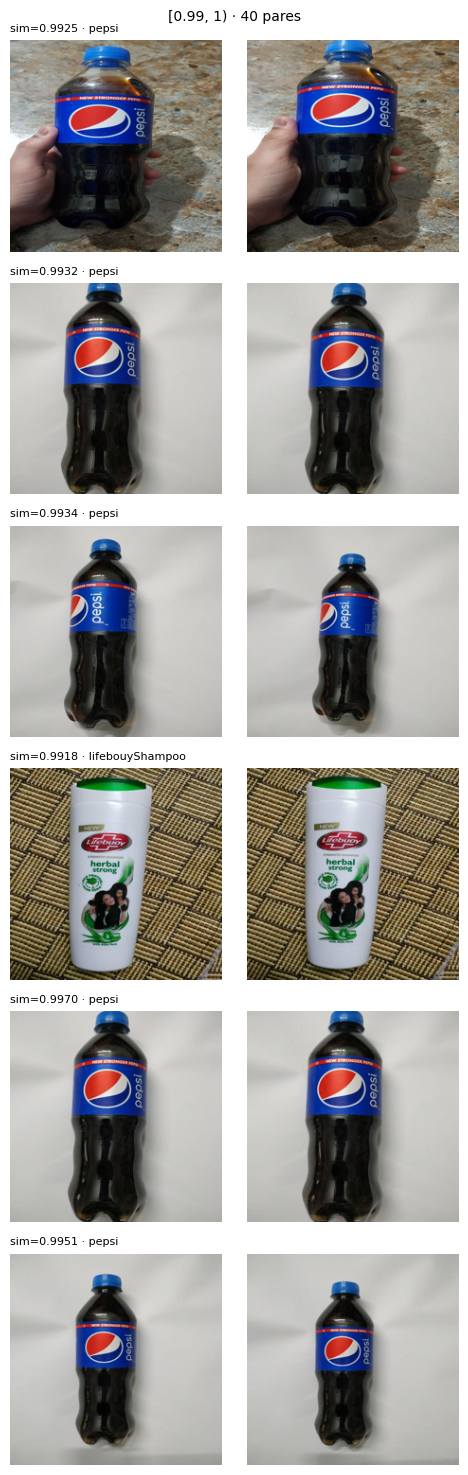

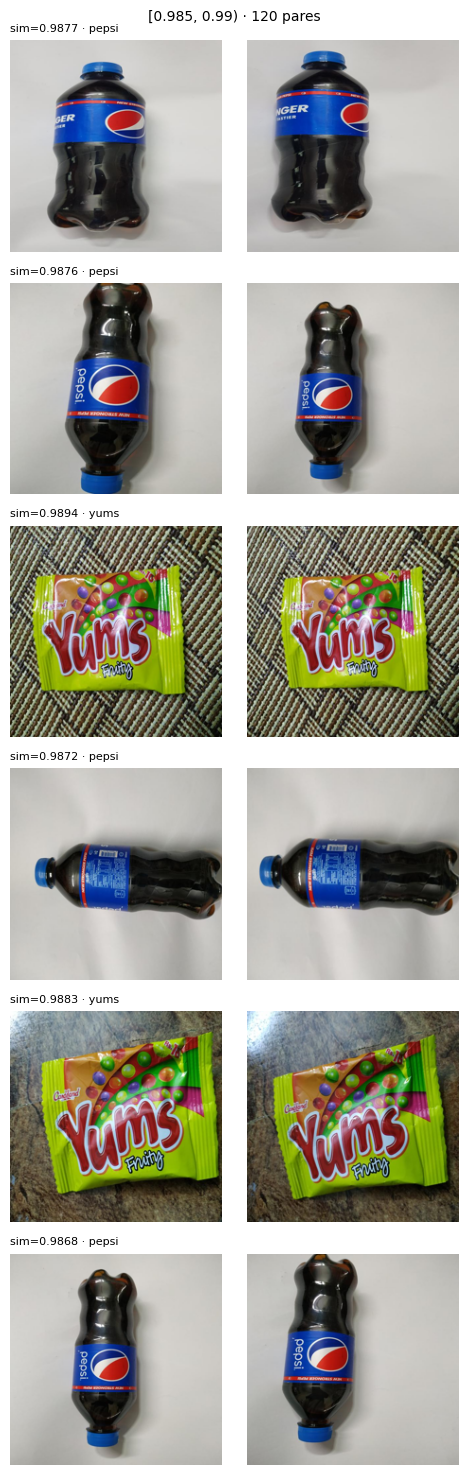

,umbral,pares,imgs_en_grupos,grupo_max,grupo_max_%clase
0,0.970,1760,1018,83,27.7
1,0.980,401,412,26,8.7
2,0.985,160,209,11,3.7
3,0.990,40,61,5,1.7
4,0.995,13,18,4,1.3


In [9]:
#Pares en los dos subrangos altos y simula los grupos que saldrían con cada umbral candidato
for lo, hi in [(0.99, 1.01), (0.985, 0.99)]:
    sub = pares[(pares["sim"] >= lo) & (pares["sim"] < hi)]
    mostrar_pares(sub, f"[{lo}, {min(hi,1)}) · {len(sub)} pares", n=6)

def simular(u):
    p = {i: i for i in keep["image_id"]}
    def r(x):
        while p[x] != x: p[x] = p[p[x]]; x = p[x]
        return x
    for a, b in pares.loc[pares["sim"] >= u, ["a", "b"]].itertuples(index=False):
        ra, rb = r(a), r(b)
        if ra != rb: p[ra] = rb
    g = keep.assign(g=keep["image_id"].map(r)).groupby(["clase", "g"]).size()
    return {"umbral": u, "pares": int((pares["sim"] >= u).sum()), "imgs_en_grupos": int(g[g > 1].sum()),
            "grupo_max": int(g.max()), "grupo_max_%clase": round(100 * g.max() / 300, 1)}

pd.DataFrame([simular(u) for u in [0.97, 0.98, 0.985, 0.99, 0.995]])

# Parte B
## Paso 8 · ⚠️ Fija el umbral

Escribe en `UMBRAL_SIM` el valor **a partir del cual consideras que dos imágenes son la misma toma**. Anota en la bitácora el valor y el motivo (qué viste en los rangos).
Los pares pHash idénticos siempre se agrupan, sea cual sea el umbral.

In [10]:
UMBRAL_SIM = 0.985   # ← por ejemplo 0.95; FÍJALO tras revisar el Paso 7
assert UMBRAL_SIM is not None, "Fija UMBRAL_SIM después de revisar los pares del Paso 7."
print("Umbral elegido:", UMBRAL_SIM)

Umbral elegido: 0.985


## Paso 9 · Formar grupos de casi duplicados (`group_id`)
Dos imágenes van al mismo grupo si su similitud ≥ umbral o si comparten pHash; los grupos se cierran por transitividad (si A≈B y B≈C, entonces A, B y C van juntas).

In [11]:
padre = {i: i for i in keep["image_id"]}
def raiz(x):
    while padre[x] != x:
        padre[x] = padre[padre[x]]; x = padre[x]
    return x
def unir(x, y):
    rx, ry = raiz(x), raiz(y)
    if rx != ry: padre[max(rx, ry)] = min(rx, ry)

for _, r in pares[pares["sim"] >= UMBRAL_SIM].iterrows():
    unir(r["a"], r["b"])
for ids in ph:
    for other in ids[1:]:
        unir(ids[0], other)

raices = keep["image_id"].map(raiz)
mapa = {rz: f"g{k:05d}" for k, rz in enumerate(sorted(raices.unique()))}
keep["group_id"] = raices.map(mapa)
tam = keep.groupby("group_id").size()
keep["group_size"] = keep["group_id"].map(tam)

print(f"Grupos: {len(tam)} | imágenes en grupos de tamaño > 1: {int((keep['group_size'] > 1).sum())}")
print("Distribución de tamaños:\n", tam.value_counts().sort_index().to_string())
por_clase = keep.groupby("clase").agg(n=("image_id", "size"), grupos=("group_id", "nunique"),
                                      grupo_max=("group_size", "max"))
por_clase["grupo_max_%"] = (100 * por_clase["grupo_max"] / por_clase["n"]).round(1)
if (por_clase["grupo_max_%"] > 10).any():
    print("\n⚠️ Hay grupos que superan el 10% de su clase: revisa si el umbral es demasiado bajo "
          "(los grupos se 'encadenan').")
por_clase

Grupos: 4974 | imágenes en grupos de tamaño > 1: 211
Distribución de tamaños:
 1     4889
2       66
3       10
4        6
6        1
8        1
11       1


,n,grupos,grupo_max,grupo_max_%
clase,,,,
01200080175-pepsi-500ml,300,235,11,3.7
0870572007376-yums-10g,300,285,4,1.3
620514018256-nationalKetchup-50g,300,294,3,1.0
7622201673222-dairyMilk-65g,300,298,2,0.7
7622201718664-tang-25g,300,300,1,0.3
8006540978313-areilSurf-40g,300,300,1,0.3
861008218328-milkpackCareem-200ml,300,299,2,0.7
8720608618972-lipton-16g,300,300,1,0.3
8886950072258-lemonMax-85g,300,300,1,0.3


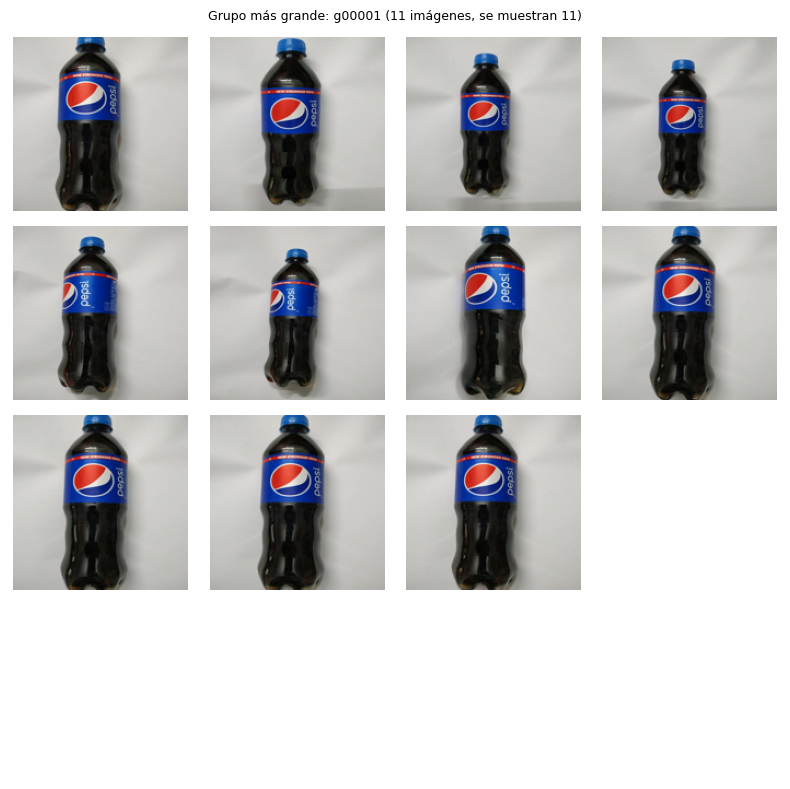

In [12]:
# Revisión visual del grupo más grande
g_max = tam.idxmax()
sub = keep[keep["group_id"] == g_max].head(16)
n = len(sub); c = int(np.ceil(np.sqrt(n)))
fig, axes = plt.subplots(c, c, figsize=(c * 2, c * 2), squeeze=False)
for ax in axes.ravel(): ax.axis("off")
for ax, (_, r) in zip(axes.ravel(), sub.iterrows()):
    with Image.open(EXTRACT_DIR / r["ruta_rel"]) as im:
        ax.imshow(im.convert("RGB").resize((160, 160)))
fig.suptitle(f"Grupo más grande: {g_max} ({tam.max()} imágenes, se muestran {n})", fontsize=9)
fig.tight_layout(); plt.show()

## Paso 10 · Partición 60/10/30 estratificada por clase y por grupo

En cada clase los grupos se barajan (semilla fija), se ordenan de mayor a menor y cada uno se asigna a la partición con mayor déficit relativo frente a su objetivo. Así:
- un grupo nunca queda repartido entre particiones,
- cada clase queda lo más cerca posible de 60/10/30.

In [14]:
rng = np.random.default_rng(SEED)
keep["split"] = None
filas_obj = []
for clase, sub in keep.groupby("clase"):
    n = len(sub)
    obj = {"train": round(n * PROPORCIONES["train"]), "val": round(n * PROPORCIONES["val"])}
    obj["test"] = n - obj["train"] - obj["val"]
    actual = {k: 0 for k in obj}
    grupos = sub.groupby("group_id").size()
    gids = rng.permutation(grupos.index.to_numpy())          # copia barajada: no altera el índice
    gids = sorted(gids, key=lambda g: -int(grupos.loc[g]))   # mayor a menor, desempate aleatorio
    for g in gids:
        dest = max(obj, key=lambda s: (obj[s] - actual[s]) / obj[s])
        keep.loc[sub.index[sub["group_id"] == g], "split"] = dest   # solo filas de esta clase
        actual[dest] += int(grupos.loc[g])
    filas_obj.append({"clase": clase, **{f"obj_{k}": v for k, v in obj.items()}})

# La tabla se construye con lo REALMENTE asignado
SPL = ["train", "val", "test"]
tabla_split = pd.DataFrame(filas_obj).set_index("clase")
real = pd.crosstab(keep["clase"], keep["split"]).reindex(columns=SPL, fill_value=0)
for s in SPL:
    tabla_split[f"real_{s}"] = real[s]
tabla_split["desvio_max"] = pd.concat(
    [(tabla_split[f"real_{s}"] - tabla_split[f"obj_{s}"]).abs() for s in SPL], axis=1).max(axis=1)

assert keep["split"].notna().all(), "Quedaron imágenes sin partición"
assert keep.groupby("group_id")["split"].nunique().max() == 1, "Un grupo quedó repartido"
assert (real.sum(axis=1) == keep["clase"].value_counts().sort_index()).all(), "Conteos inconsistentes"
print(keep["split"].value_counts().reindex(SPL).to_string())
if (tabla_split["desvio_max"] > 3).any():
    print("⚠️ Alguna clase se desvía más de 3 imágenes del objetivo")
tabla_split

split
train    3060
val       510
test     1530


,obj_train,obj_val,obj_test,real_train,real_val,real_test,desvio_max
clase,,,,,,,
01200080175-pepsi-500ml,180,30,90,180,30,90,0
0870572007376-yums-10g,180,30,90,180,30,90,0
620514018256-nationalKetchup-50g,180,30,90,180,30,90,0
7622201673222-dairyMilk-65g,180,30,90,180,30,90,0
7622201718664-tang-25g,180,30,90,180,30,90,0
8006540978313-areilSurf-40g,180,30,90,180,30,90,0
861008218328-milkpackCareem-200ml,180,30,90,180,30,90,0
8720608618972-lipton-16g,180,30,90,180,30,90,0
8886950072258-lemonMax-85g,180,30,90,180,30,90,0


## Paso 11 · Verificaciones de la partición

In [15]:
# 1) Ningún grupo en más de una partición
assert keep.groupby("group_id")["split"].nunique().max() == 1, "Un grupo quedó repartido"
# 2) Ninguna pareja val/test ↔ train por encima del umbral (fuga), dentro de cada clase
fuga = 0
max_sim_eval = np.zeros(len(keep))
for clase, sub in keep.groupby("clase"):
    tr = np.array([pos[i] for i in sub.loc[sub["split"] == "train", "image_id"]])
    ev = np.array([pos[i] for i in sub.loc[sub["split"] != "train", "image_id"]])
    S = En[ev] @ En[tr].T
    max_sim_eval[ev] = S.max(1)
    fuga += int((S >= UMBRAL_SIM).any(1).sum())
keep["max_sim_a_train"] = np.where(keep["split"] == "train", np.nan, max_sim_eval)
assert fuga == 0, f"{fuga} imágenes de val/test tienen un casi duplicado en train"
# 3) Las estadísticas de imagen se parecen entre particiones (sanity check)
stats = ["brillo_medio", "contraste_std", "saturacion_media", "nitidez_lapvar"]
print("Sin grupos repartidos ✔ | Sin fuga por encima del umbral ✔\n")
print("Medianas por partición:")
keep.groupby("split")[stats].median().reindex(["train", "val", "test"]).round(1)

Sin grupos repartidos ✔ | Sin fuga por encima del umbral ✔

Medianas por partición:


,brillo_medio,contraste_std,saturacion_media,nitidez_lapvar
split,,,,
train,110.0,53.3,80.8,367.3
val,112.6,52.6,78.8,376.4
test,111.4,53.5,80.4,358.2


## Paso 12 · Mapa t-SNE de los embeddings (por clase y por partición)
Sirve como figura descriptiva: las particiones deberían mezclarse dentro de cada nube de clase.

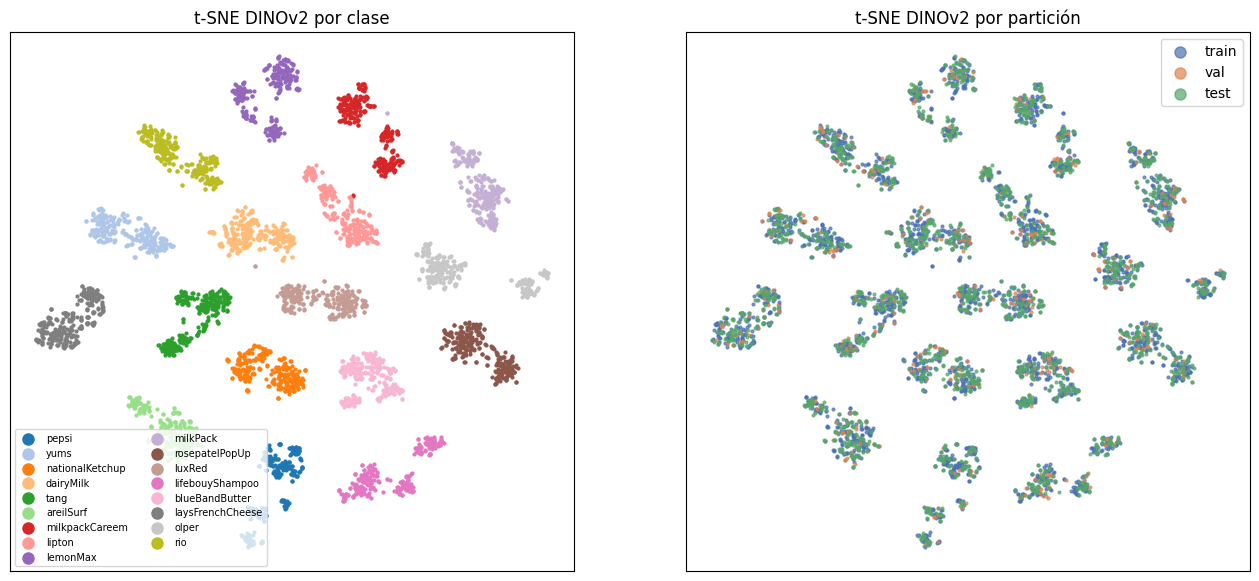

In [16]:
Z = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(En)
keep["tsne_x"], keep["tsne_y"] = Z[:, 0], Z[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
cmap = plt.get_cmap("tab20")
for k, (clase, sub) in enumerate(keep.groupby("clase")):
    nombre = clase.split("-")[1] if clase.count("-") >= 2 else clase
    axes[0].scatter(sub["tsne_x"], sub["tsne_y"], s=4, color=cmap(k % 20), label=nombre)
axes[0].legend(markerscale=4, fontsize=7, ncol=2); axes[0].set_title("t-SNE DINOv2 por clase")
for s, col in zip(["train", "val", "test"], ["#4C72B0", "#DD8452", "#55A868"]):
    sub = keep[keep["split"] == s]
    axes[1].scatter(sub["tsne_x"], sub["tsne_y"], s=4, color=col, label=s, alpha=0.7)
axes[1].legend(markerscale=4); axes[1].set_title("t-SNE DINOv2 por partición")
for ax in axes: ax.set_xticks([]); ax.set_yticks([])
fig.savefig(DIRS["eda"] / "02_tsne_clase_particion.png", dpi=200, bbox_inches="tight"); plt.show()

## Paso 13 · Línea base de distancias al vecino más cercano (para memorización)

Para cada imagen real se guardan las **10 distancias l2 más cortas** a imágenes de *entrenamiento* (en el espacio DINOv2 sin normalizar), y los ids de esos vecinos:
- `train → train` (excluyendo la propia imagen),
- `val → train` y `test → train`.

`test → train` es la referencia clave: describe cuán cerca queda de entrenamiento una imagen **real nueva**. Más adelante, si las sintéticas quedan sistemáticamente mucho más cerca de entrenamiento que eso, es señal de copia.
La fórmula exacta de calibración se fijará en la fase de evaluación tras verificarla en la fuente; aquí se guarda la materia prima.

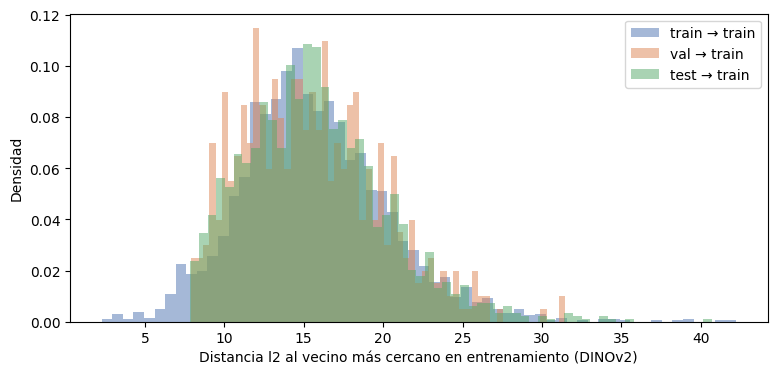

,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
train,3060.0,15.691,4.686,2.275,12.600,15.222,18.419,42.216
val,510.0,15.556,4.363,7.879,12.075,15.174,18.308,31.479
test,1530.0,15.803,4.471,7.849,12.578,15.380,18.394,40.718


In [17]:
K = 10
tr_ids = keep.loc[keep["split"] == "train", "image_id"].to_numpy()
Etr = E[[pos[i] for i in tr_ids]].astype(np.float64)
sq_tr = (Etr ** 2).sum(1)

def k_vecinos(ids, excluir_self):
    X = E[[pos[i] for i in ids]].astype(np.float64)
    D2 = (X ** 2).sum(1)[:, None] + sq_tr[None, :] - 2 * X @ Etr.T
    D = np.sqrt(np.clip(D2, 0, None))
    if excluir_self:
        D[np.arange(len(ids)), np.arange(len(ids))] = np.inf
    o = np.argsort(D, axis=1)[:, :K]
    return np.take_along_axis(D, o, 1), tr_ids[o]

registros = {}
for s in ["train", "val", "test"]:
    ids = tr_ids if s == "train" else keep.loc[keep["split"] == s, "image_id"].to_numpy()
    d, v = k_vecinos(ids, excluir_self=(s == "train"))
    registros[s] = (ids, d, v)
    keep.loc[keep["image_id"].isin(ids), "nn1_l2_train"] = pd.Series(d[:, 0], index=ids).reindex(
        keep.loc[keep["image_id"].isin(ids), "image_id"]).to_numpy()

np.savez_compressed(DIRS["embeddings"] / "nn_baseline_real_v1.npz",
                    **{f"{s}_ids": r[0] for s, r in registros.items()},
                    **{f"{s}_dist": r[1] for s, r in registros.items()},
                    **{f"{s}_vecinos": r[2] for s, r in registros.items()})

fig, ax = plt.subplots(figsize=(9, 4))
for s, col in zip(["train", "val", "test"], ["#4C72B0", "#DD8452", "#55A868"]):
    ax.hist(registros[s][1][:, 0], bins=60, alpha=0.5, density=True, color=col, label=f"{s} → train")
ax.set_xlabel("Distancia l2 al vecino más cercano en entrenamiento (DINOv2)")
ax.set_ylabel("Densidad"); ax.legend()
fig.savefig(DIRS["eda"] / "02_baseline_nn_l2.png", dpi=200, bbox_inches="tight"); plt.show()
keep.groupby("split")["nn1_l2_train"].describe().reindex(["train", "val", "test"]).round(3)

## Paso 14 · Guardar manifiesto v1, partición y zip con carpetas por partición/clase

In [18]:
m_v1 = m.merge(keep[["image_id", "nn_sim_intraclase", "group_id", "group_size", "split",
                     "max_sim_a_train", "nn1_l2_train", "tsne_x", "tsne_y"]], on="image_id", how="left")
m_v1["split"] = m_v1["split"].fillna("excluida")
m_v1.to_csv(DIRS["manifest"] / "manifest_v1.csv", index=False)

split_v1 = m_v1[~m_v1["excluir"]][["image_id", "ruta_rel", "clase", "group_id", "split"]]
split_v1.to_csv(DIRS["splits"] / "split_v1.csv", index=False)
pares.to_csv(DIRS["eda"] / "02_pares_similitud.csv", index=False)
inter.to_csv(DIRS["eda"] / "02_pares_entre_clases.csv", index=False)

# Carpetas train/val/test/<clase>/<image_id>.<ext>: copia de los archivos ORIGINALES (sin recomprimir)
SPLIT_DIR = LOCAL_DIR / "grocpos_split_v1"
if SPLIT_DIR.exists(): shutil.rmtree(SPLIT_DIR)
for _, r in tqdm(split_v1.iterrows(), total=len(split_v1), desc="Copiando"):
    dst = SPLIT_DIR / r["split"] / r["clase"] / f"{r['image_id']}{Path(r['ruta_rel']).suffix.lower()}"
    dst.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(EXTRACT_DIR / r["ruta_rel"], dst)
ZIP_SPLIT = shutil.make_archive(str(LOCAL_DIR / "grocpos_split_v1"), "zip", root_dir=SPLIT_DIR)
shutil.copy2(ZIP_SPLIT, DIRS["splits"] / "grocpos_split_v1.zip")
SHA_SPLIT = sha256_file(DIRS["splits"] / "grocpos_split_v1.zip")
print("Guardado en Drive: manifest_v1.csv, split_v1.csv, grocpos_split_v1.zip")
print("SHA-256 del zip de partición:", SHA_SPLIT)

Copiando:   0%|          | 0/5100 [00:00<?, ?it/s]

Guardado en Drive: manifest_v1.csv, split_v1.csv, grocpos_split_v1.zip
SHA-256 del zip de partición: 9c55ca15c59cfbec24ae05da3b4eefccf63a7e90367c3583ef72b6acb8e7d469


## Paso 15 · Registro y resumen

In [19]:
log02 = {
    "fecha_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "zip_origen_sha256": LOG01["zip"]["sha256"],
    "exclusiones": m["motivo_exclusion"].replace("", "conservada").value_counts().to_dict(),
    "embeddings": EMB_CFG,
    "umbral_similitud": UMBRAL_SIM,
    "similitud_pares_phash": [round(x, 4) for x in ref_phash],
    "n_grupos": int(len(tam)),
    "imagenes_en_grupos_multiples": int((keep["group_size"] > 1).sum()),
    "grupo_max": int(tam.max()),
    "proporciones": PROPORCIONES,
    "conteo_split": keep["split"].value_counts().to_dict(),
    "desvio_max_por_clase": int(tabla_split["desvio_max"].max()),
    "fuga_val_test": fuga,
    "zip_split_sha256": SHA_SPLIT,
    "versiones": {"numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__},
    "seed": SEED,
}
(DIRS["logs"] / "02_preparacion.json").write_text(json.dumps(log02, indent=2, ensure_ascii=False, default=str))
print(json.dumps({k: log02[k] for k in ["exclusiones", "umbral_similitud", "n_grupos",
                                         "imagenes_en_grupos_multiples", "grupo_max", "conteo_split",
                                         "desvio_max_por_clase", "fuga_val_test"]},
                 indent=2, ensure_ascii=False, default=str))

{
  "exclusiones": {
    "conservada": 5100,
    "duplicado_md5": 103
  },
  "umbral_similitud": 0.985,
  "n_grupos": 4974,
  "imagenes_en_grupos_multiples": 211,
  "grupo_max": 11,
  "conteo_split": {
    "train": 3060,
    "test": 1530,
    "val": 510
  },
  "desvio_max_por_clase": 0,
  "fuga_val_test": 0
}


### Checklist antes del notebook 03
- [ ] Anotaste en la bitácora el umbral, el porqué, y el SHA-256 del zip de partición.
- [ ] Revisaste los pares entre clases (`eda/02_pares_entre_clases.csv`) por si hay errores de etiqueta.
- [ ] La partición quedó en 180/30/90 por clase (o con desvío mínimo) y sin fuga.
- [ ] **Regla de oro desde ahora:** las imágenes de `test` no se abren para entrenar, ajustar ni elegir checkpoints.

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,k,silhouette,tamanos_modos
clase,,,
01200080175-pepsi-500ml,2,0.474,"[247, 53]"
0870572007376-yums-10g,3,0.360,"[118, 139, 43]"
620514018256-nationalKetchup-50g,2,0.291,"[148, 152]"
7622201673222-dairyMilk-65g,4,0.289,"[51, 104, 17, 128]"
7622201718664-tang-25g,3,0.364,"[30, 177, 93]"
8006540978313-areilSurf-40g,2,0.328,"[74, 226]"
861008218328-milkpackCareem-200ml,3,0.407,"[90, 157, 53]"
8720608618972-lipton-16g,4,0.334,"[43, 145, 51, 61]"
8886950072258-lemonMax-85g,4,0.324,"[34, 141, 65, 60]"


split                                        train  val  test
clase                               modo_id                  
01200080175-pepsi-500ml             0          152   25    70
                                    1           28    5    20
0870572007376-yums-10g              0           76    9    33
                                    1           77   16    46
                                    2           27    5    11
620514018256-nationalKetchup-50g    0           92   13    43
                                    1           88   17    47
7622201673222-dairyMilk-65g         0           27    7    17
                                    1           61   13    30
                                    2           10    2     5
                                    3           82    8    38
7622201718664-tang-25g              0           19    3     8
                                    1          112   14    51
                                    2           49   13    31
8006540978313-areilSurf-40g         0           46    5    23
                                    1          134   25    67
861008218328-milkpackCareem-200ml   0           52   12    26
                                    1           96   12    49
                                    2           32    6    15
8720608618972-lipton-16g            0           22    4    17
                                    1           89   18    38
                                    2           30    6    15
                                    3           39    2    20
8886950072258-lemonMax-85g          0           17    5    12
                                    1           86   13    42
                                    2           39    8    18
                                    3           38    4    18
891008219561-milkPack-1lr           0          120   21    57
                                    1           60    9    33
8961006040044-rosepatelPopUp-2Ply   0           67   10    39
                                    1          113   20    51
8961014013627-luxRed-140g           0           79   11    39
                                    1          101   19    51
8961014246834-lifebouyShampoo-175ml 0           42    5    18
                                    1           50    7    30
                                    2           88   18    42
8961102110306-blueBandButter-235g   0           66   10    33
                                    1          114   20    57
8964000090619-laysFrenchCheese-14g  0           70   13    40
                                    1          110   17    50
8964000346334-olper-1.5ltr          0          121   22    59
                                    1           59    8    31
8964002759095-rio-70g               0          100   19    54
                                    1           80   11    36

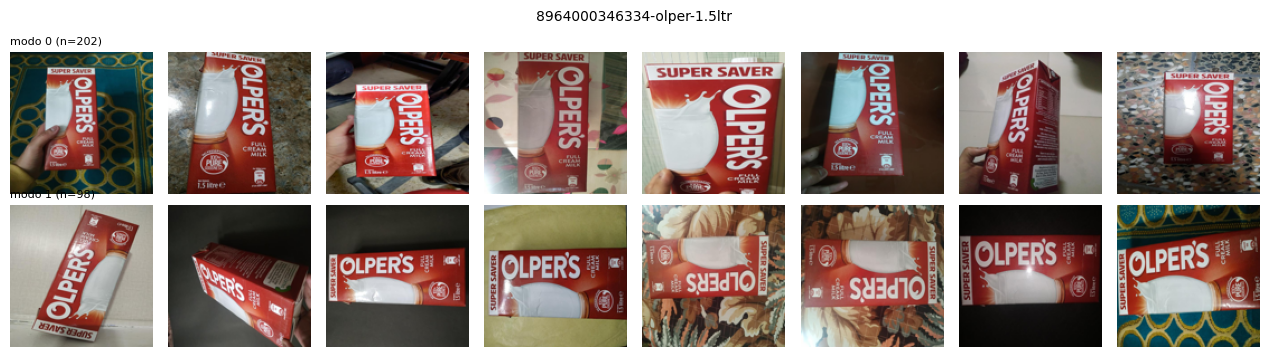

In [21]:
import json, zipfile, shutil
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from google.colab import drive
drive.mount("/content/drive")

P = Path("/content/drive/MyDrive/tesis_retail")
LOCAL = Path("/content/data"); LOCAL.mkdir(exist_ok=True)
EXTRACT = LOCAL / "grocpos_v4"
if not EXTRACT.exists():
    zip_name = json.loads((P / "logs/01_inventario.json").read_text())["zip"]["nombre"]
    shutil.copy2(P / "raw" / zip_name, LOCAL / zip_name)
    zipfile.ZipFile(LOCAL / zip_name).extractall(EXTRACT)

m = pd.read_csv(P / "manifest/manifest_v1.csv")
EMB = np.load(P / "embeddings/dinov2_vitl14_v0.npy")
assert pd.read_csv(P / "embeddings/dinov2_vitl14_v0_ids.csv")["image_id"].tolist() == m["image_id"].tolist()
keep = m[~m["excluir"]].copy()
En = EMB[keep.index.to_numpy()]
En = En / np.linalg.norm(En, axis=1, keepdims=True)
keep["modo_id"] = -1
resumen = []

for clase, sub in keep.groupby("clase"):
    X = En[keep.index.get_indexer(sub.index)]
    mejor = (1, -1.0, np.zeros(len(sub), dtype=int))
    for k in [2, 3, 4]:
        lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
        s = silhouette_score(X, lab, metric="cosine")
        if s > mejor[1]:
            mejor = (k, s, lab)
    k, s, lab = mejor
    keep.loc[sub.index, "modo_id"] = lab
    tam = pd.Series(lab).value_counts().sort_index().tolist()
    resumen.append({"clase": clase, "k": k, "silhouette": round(float(s), 3), "tamanos_modos": tam})

resumen = pd.DataFrame(resumen).set_index("clase")
display(resumen)

# Cada modo debe estar presente en train y test (si no, la evaluación por modo no sería posible)
cob = pd.crosstab([keep["clase"], keep["modo_id"]], keep["split"])[["train", "val", "test"]]
display(cob)

def ver_modos(clase, n=8):
    sub = keep[keep["clase"] == clase]
    modos = sorted(sub["modo_id"].unique())
    fig, axes = plt.subplots(len(modos), n, figsize=(n * 1.6, len(modos) * 1.8), squeeze=False)
    for i, mo in enumerate(modos):
        muestra = sub[sub["modo_id"] == mo].sample(min(n, (sub["modo_id"] == mo).sum()), random_state=42)
        for ax in axes[i]: ax.axis("off")
        for ax, (_, r) in zip(axes[i], muestra.iterrows()):
            with Image.open(EXTRACT / r["ruta_rel"]) as im:
                ax.imshow(im.convert("RGB").resize((128, 128)))
        axes[i, 0].set_title(f"modo {mo} (n={int((sub['modo_id'] == mo).sum())})", fontsize=8, loc="left")
    fig.suptitle(clase, fontsize=10); fig.tight_layout()
    (P / "eda/modos").mkdir(parents=True, exist_ok=True)
    fig.savefig(P / "eda/modos" / f"modos_{clase}.png", dpi=150, bbox_inches="tight")
    plt.show()

ver_modos("8964000346334-olper-1.5ltr")

keep[["image_id", "modo_id"]].to_csv(P / "manifest/modos_v1.csv", index=False)
resumen.to_csv(P / "eda/02b_resumen_modos.csv")